# heatwaves_monthly_CESM2.ipynb
## Calculate marine heatwaves with CESM2 using the 90th (and 10th) percentile of monthly data.

#### Created by Brendan Myers
##### 09/02/2026

In [1]:
%load_ext autoreload
%autoreload 2
import os
from glob import glob
from collections import OrderedDict
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import pop_tools 
from statistics import mean
from matplotlib import style
from scipy import stats

import xmhw

/glade/work/brendanmy/conda-envs/bgc-env/lib/python3.13/site-packages/pop_tools/__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


## Create Dask Cluster

In [2]:
try:
    client.shutdown()
except:
    pass

In [3]:
import dask
from DaskSetup import DaskSetup

try:
    client.shutdown()
except:
    pass

dask.config.set({'logging.distributed': 'error'})

cluster, client = DaskSetup.get_ClusterClient(memory='25GB', walltime='03:00:00', account='P93300070')
# cluster.scale(12) 
cluster.adapt(minimum_jobs=10, maximum_jobs=30)
print(cluster.job_script())
# client

#!/usr/bin/env bash

#PBS -N dask-worker
#PBS -q casper
#PBS -A P93300070
#PBS -l select=1:ncpus=1:mem=25GB
#PBS -l walltime=03:00:00
#PBS -e /glade/derecho/scratch/brendanmy/dask_logs//
#PBS -o /glade/derecho/scratch/brendanmy/dask_logs//
export ESMFMKFILE=/glade/work/brendanmy/conda-envs/bgc-env/lib/esmf.mk
/glade/work/brendanmy/conda-envs/bgc-env/bin/python -m distributed.cli.dask_worker tcp://128.117.208.180:46657 --name dummy-name --nthreads 2 --memory-limit 23.28GiB --nanny --death-timeout 60 --local-directory /glade/derecho/scratch/brendanmy/dask_logs/ --interface ext



In [4]:
client.wait_for_workers(1)
client

<Client: 'tcp://128.117.208.180:46657' processes=0 threads=0, memory=0 B>

# Open Data

### Get grid info: we need a land/ocean mask, lats, lons, and major basin masks

In [5]:
### First, get the pop grid information, so we have lon, lat
ds_grid = pop_tools.get_grid('POP_gx1v7')
lats = ds_grid.TLAT
lons = ds_grid.TLONG

In [6]:
### Second, create an empty ones array on the model grid
ones = np.full((384,320),1,dtype=int)
ones = xr.DataArray(ones,dims=('nlat','nlon'))

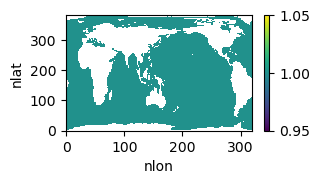

In [7]:
### third, use the REGION_MASK variable and the ones array to create a land mask
ones = ones.where(ds_grid.REGION_MASK>0)
ones.plot(figsize=(3,1.5))

In [8]:
### forth, get the major basins mask 
major_basins = xr.open_dataset('/glade/work/kristenk/ocean_masks/major_basins.nc')

major_basins = major_basins.basin.values
major_basins = xr.DataArray(major_basins, dims=('nlat','nlon'))

### Get the model FOSI run

In [9]:
case = 'g.e22.GOMIPECOIAF_JRA-1p4-2018.TL319_g17.4p2z.002branch'
path = '/glade/campaign/cesm/development/bgcwg/projects/CESM2-OMIP2-like-4p2z-run/'+case+'/ocn/proc/tseries/month_1/'

In [10]:
# variables = ['IFRAC','HMXL','diatChl','spChl','coccoChl','diazChl','TEMP']
variables = ['TEMP']

In [11]:
def preprocess(ds):
    ds = ds.isel(z_t=0)
    ds = ds.isel(z_t_150m=0)
    return ds

In [12]:
ds_fosi = xr.Dataset()

for var in variables:
    
    print('starting on ', var)
    ################ FOSI
    
    #ds_tmp = xr.open_dataset(path+case+'.pop.h.'+var+'.??????-??????.nc')
    #ds_tmp['time'] = time
    
    files = sorted(glob(f'{path}/{case}.pop.h.{var}.??????-??????.nc'))       
    ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time",
                       drop_variables=["transport_components", "transport_regions"], decode_times=True, preprocess=preprocess, combine='nested')

    keep_vars=['z_t','z_t_150m','time_bound','dz','TLAT','TLONG','time','KMT'] + [var]

    ds_tmp = ds_tmp.drop_vars([v for v in ds_tmp.variables if v not in keep_vars])
        
    ds_fosi = xr.merge([ds_fosi,ds_tmp], compat='override')

starting on  TEMP


### Make a mean of the time bounds (CESM-specific)

In [13]:
ds_fosi["time"] = ds_fosi.time_bound.compute().mean(dim="d2")

### trim to the satellite period since 2003

In [14]:
ds_fosi.time[540:768]

<xarray.DataArray 'time' (time: 228)> Size: 2kB
array([cftime.DatetimeNoLeap(2003, 1, 16, 12, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2003, 2, 15, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2003, 3, 16, 12, 0, 0, 0, has_year_zero=True),
       ...,
       cftime.DatetimeNoLeap(2021, 10, 16, 12, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2021, 11, 16, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2021, 12, 16, 12, 0, 0, 0, has_year_zero=True)],
      shape=(228,), dtype=object)
Coordinates:
  * time      (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    z_t       float32 4B 500.0
    z_t_150m  float32 4B 500.0
Attributes:
    long_name:     boundaries for time-averaging interval
    cell_methods:  time: mean

In [15]:
### slice the data
ds_fosi = ds_fosi.isel(time=slice(540,768))

In [16]:
ds_fosi.load()

<xarray.Dataset> Size: 115MB
Dimensions:     (nlat: 384, nlon: 320, time: 228, d2: 2)
Coordinates:
  * time        (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    TLAT        (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG       (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... nan nan nan
    z_t         float32 4B 500.0
    z_t_150m    float32 4B 500.0
Dimensions without coordinates: nlat, nlon, d2
Data variables:
    KMT         (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    TEMP        (time, nlat, nlon) float32 112MB nan nan nan nan ... nan nan nan
    dz          float32 4B 1e+03
    time_bound  (time, d2) object 4kB 2003-01-01 00:00:00 ... 2022-01-01 00:0...

In [17]:
import psutil
import os

# Get current process memory usage in MB
process = psutil.Process(os.getpid())
mem_info = process.memory_info()
print(f"Memory usage: {mem_info.rss / 1024 ** 3:.2f} GB")


Memory usage: 0.71 GB


# A few precalculations....

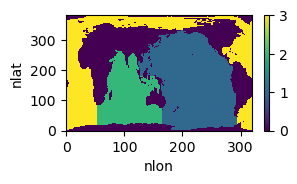

In [18]:
major_basins.plot(figsize=(3,1.5))

### Assign basins

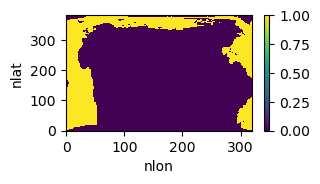

In [19]:
Atlantic = ones.where(major_basins == 3, other=0)
#.where(major_basins.basin == 3) #ones.where(ds_grid.REGION_MASK >= 5, other=0).where(ds_grid.REGION_MASK<10, other=0)
Atlantic.plot(figsize=(3,1.5))

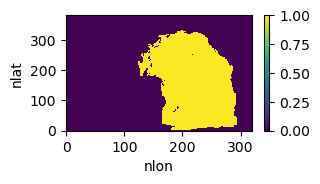

In [20]:
Pacific = ones.where(major_basins == 1, other=0)
Pacific.plot(figsize=(3,1.5))

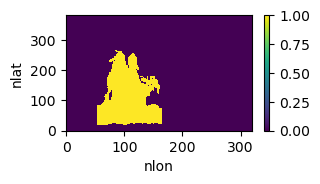

In [21]:
Indian = ones.where(major_basins == 2, other=0)
Indian.plot(figsize=(3,1.5))

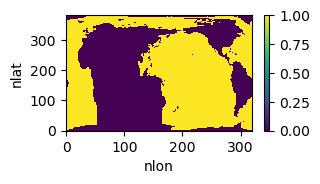

In [22]:
Atlantic_Pacific = Atlantic + Pacific
Atlantic_Pacific.plot(figsize=(3,1.5))

In [23]:
ds_fosi['basin_mask'] = major_basins
ds_fosi

<xarray.Dataset> Size: 116MB
Dimensions:     (nlat: 384, nlon: 320, time: 228, d2: 2)
Coordinates:
  * time        (time) object 2kB 2003-01-16 12:00:00 ... 2021-12-16 12:00:00
    TLAT        (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG       (nlat, nlon) float64 983kB 320.6 321.7 322.8 ... nan nan nan
    z_t         float32 4B 500.0
    z_t_150m    float32 4B 500.0
Dimensions without coordinates: nlat, nlon, d2
Data variables:
    KMT         (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... nan nan nan nan
    TEMP        (time, nlat, nlon) float32 112MB nan nan nan nan ... nan nan nan
    dz          float32 4B 1e+03
    time_bound  (time, d2) object 4kB 2003-01-01 00:00:00 ... 2022-01-01 00:0...
    basin_mask  (nlat, nlon) float64 983kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0

In [24]:
ds_fosi['TEMP_anom'] = ds_fosi['TEMP'] - ds_fosi['TEMP'].mean(dim='time')
ds_fosi['TEMP_anom'].attrs = ds_fosi['TEMP_anom'].attrs | {'long_name': 'Potential Temperature Anomoly'}

# Calc Heatwaves

## Monthly

In [67]:
# Need groupby to do this by month
quantile_upp = ds_fosi.TEMP_anom.groupby('time.month').quantile(0.9, dim='time', skipna=True)
quantile_low = ds_fosi.TEMP_anom.groupby('time.month').quantile(0.1, dim='time', skipna=True)

tmp_g = ds_fosi.groupby('time.month')

mon_sep_list_mhw = []
mon_sep_list_mcw = []
for mon in range(1,13):
    tmp = tmp_g[mon]
    mon_sep_list_mhw.append(tmp.TEMP_anom.where((tmp.TEMP_anom>=quantile_upp[mon-1]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['month']))
    mon_sep_list_mcw.append(tmp.TEMP_anom.where((tmp.TEMP_anom<=quantile_low[mon-1]) | (ds_fosi.TEMP_anom.isnull()), other=-9999).drop_vars(['month']))

ds_fosi['MHW'] = xr.concat(mon_sep_list_mhw, dim='time', coords='minimal').sortby('time').rename('MHW')
ds_fosi['MHW'].attrs = ds_fosi['MHW'].attrs | {'quantile': quantile_upp['quantile'].item()}
ds_fosi['MCW'] = xr.concat(mon_sep_list_mcw, dim='time', coords='minimal').sortby('time').rename('MCW')
ds_fosi['MCW'].attrs = ds_fosi['MCW'].attrs | {'quantile': quantile_low['quantile'].item()}

ds_fosi = ds_fosi.drop_vars('quantile')
# # # ds_fosi.TEMP_anom.where(quantile_per_month(ds_fosi.TEMP_anom, quantile_90, greater_less='>'), other=-9999)
# ds_fosi['mhw'] = ds_fosi.TEMP_anom.where((ds_fosi.TEMP_anom>=quantile_90) | (ds_fosi.TEMP_anom.isnull()), other=-9999)  #want to separate land nans from these nans
# ds_fosi['mcw'] = ds_fosi.TEMP_anom.where((ds_fosi.TEMP_anom<=quantile_10) | (ds_fosi.TEMP_anom.isnull()), other=-9999)  

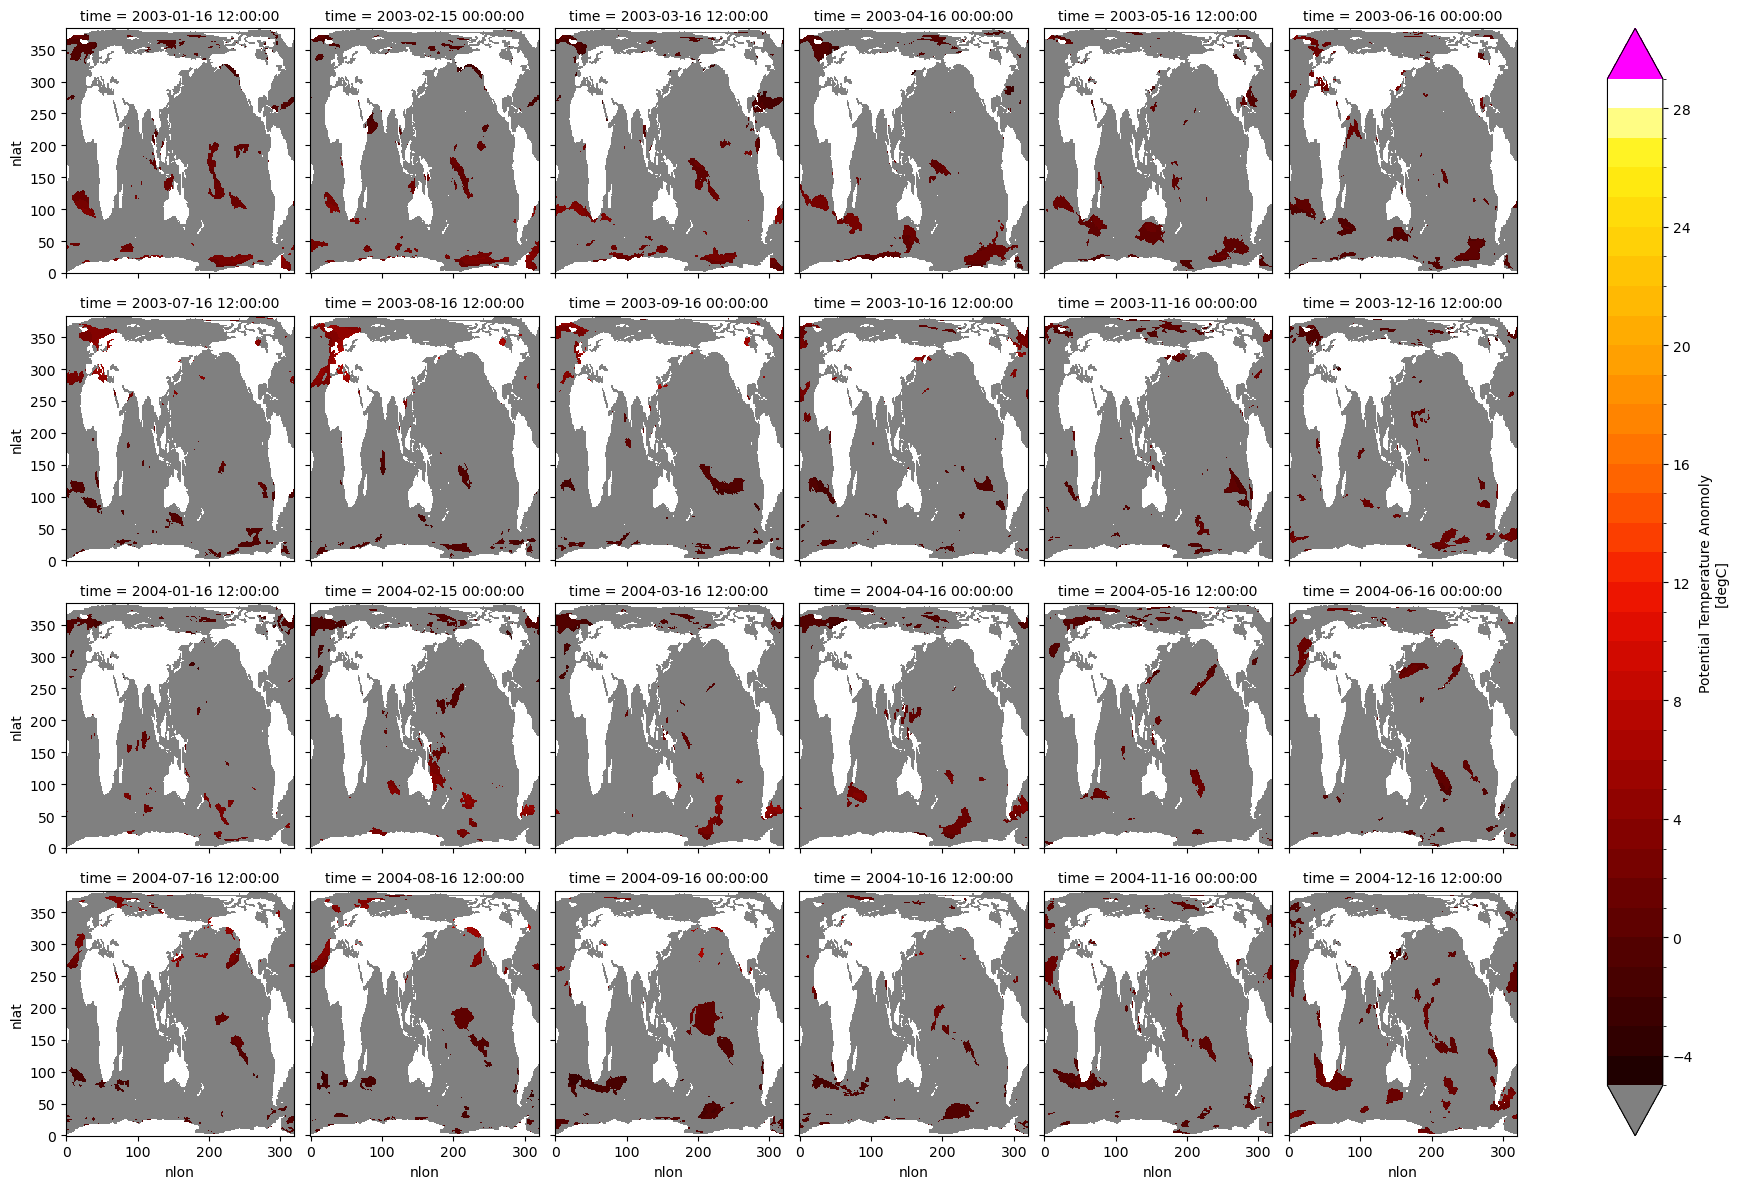

In [63]:
import colorcet as cc
cmap_hw = cc.cm.fire
cmap_hw.set_over("magenta")  # Color for data above vmax
cmap_hw.set_under("grey")

ds_fosi.isel(time=slice(0,24)).MHW.plot(col='time', col_wrap=6, cmap=cmap_hw, levels=np.arange(-5, 30, 1), cbar_kwargs={'extend':'both'})

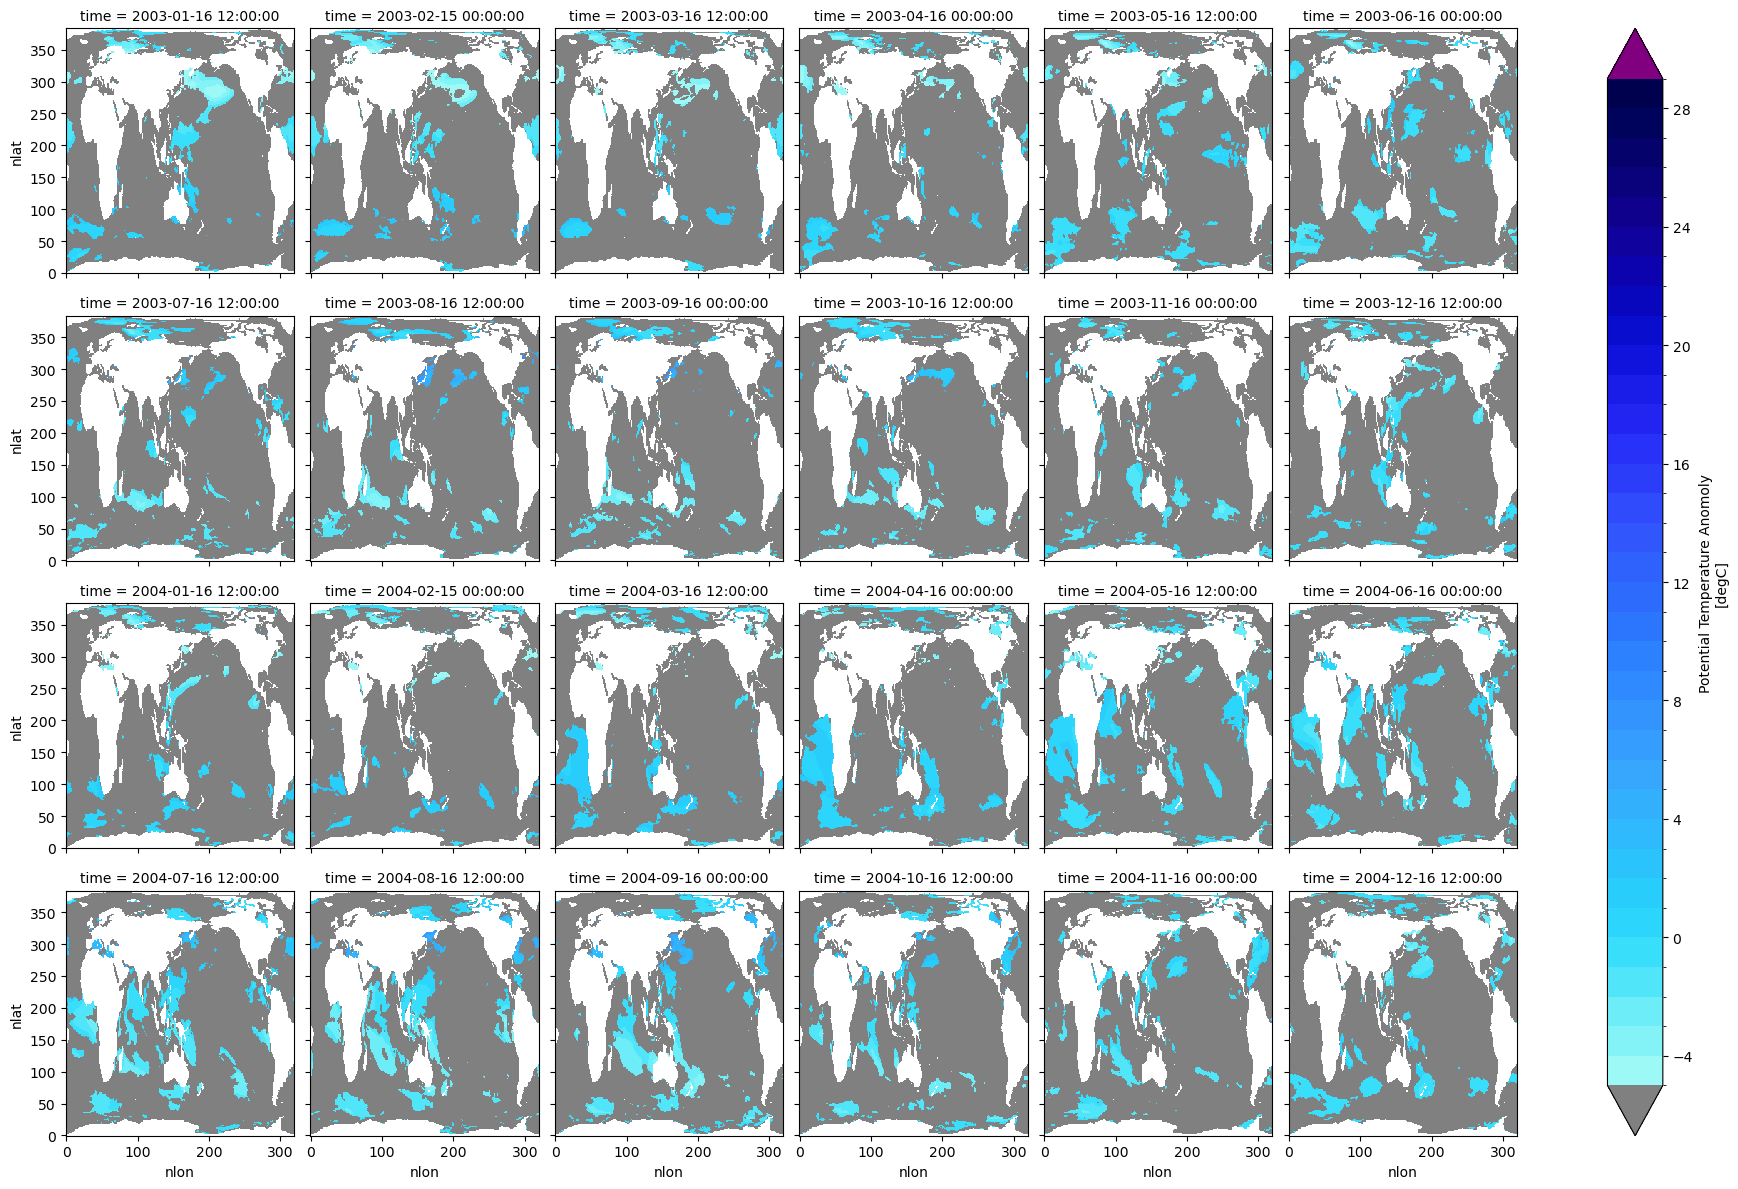

In [64]:
cmap_hw = cc.cm.kbc_r
cmap_hw.set_over("purple")  # Color for data above vmax
cmap_hw.set_under("grey")

ds_fosi.isel(time=slice(0,24)).MCW.plot(col='time', col_wrap=6, cmap=cmap_hw, levels=np.arange(-5, 30, 1), cbar_kwargs={'extend':'both'})

In [ ]:
# Frequency of MHW
### SINCE THIS IS QUANTILE PER LOCATION IT DOESN'T MAKE SENSE, will always be 2

def freq_ufunc(arr):
    not_nan = arr[~np.isnan(arr)]
    if len(not_nan)!=0:
        not_nan = not_nan[not_nan!=-9999]
        freq = len(not_nan)/len(arr)
    else:
        freq = np.nan
    return freq

def frequency_per_mon(groups):
    res_list = []
    var_list = ['MHW', 'MCW']
    for var in var_list:
        result = xr.apply_ufunc(freq_ufunc,
                                groups[var],
                                input_core_dims=[['time']],
                                output_core_dims=[[]],
                                vectorize=True,
                                dask="parallelized",
                                on_missing_core_dim='copy'
                                )
        result = result.rename(var+'_FREQ')
        result.attrs = {'long_name': 'Frequency of Marine Heatwave/Coldwave Events, normalized by time', 'units': ''}
        res_list.append(result)
    out = xr.merge(res_list)
    return out

# Apply the custom function using groupby and map
ds_frequency = ds_fosi.groupby("time.month").map(frequency_per_mon)#.plot(levels=np.arange(0, 1.1, .1), col='month', col_wrap=3)

<xarray.Dataset> Size: 26MB
Dimensions:   (month: 12, nlat: 384, nlon: 320)
Coordinates:
  * month     (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
    TLAT      (nlat, nlon) float64 983kB -79.22 -79.22 -79.22 ... nan nan nan
    TLONG     (nlat, nlon) float64 983kB 320.6 321.7 322.8 323.9 ... nan nan nan
    z_t       float32 4B 500.0
    z_t_150m  float32 4B 500.0
Dimensions without coordinates: nlat, nlon
Data variables:
    MHW_FREQ  (month, nlat, nlon) float64 12MB nan nan nan nan ... nan nan nan
    MCW_FREQ  (month, nlat, nlon) float64 12MB nan nan nan nan ... nan nan nan
Attributes:
    long_name:  Frequency of Marine Heatwave/Coldwave Events, normalized by time
    units:

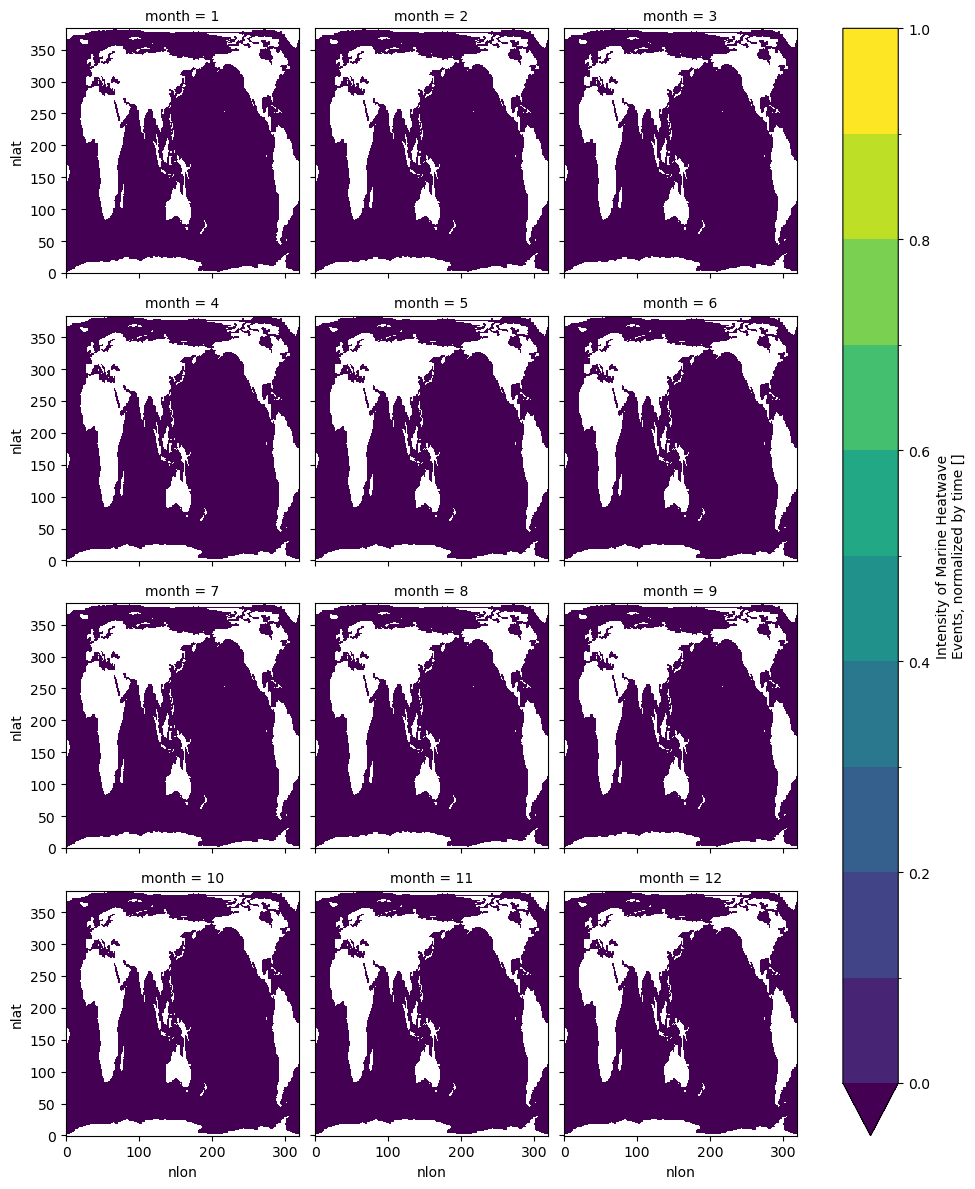

In [ ]:
### Intensity of MHW's
import scipy.stats as stats

def intense_ufunc(ex_arr, t_arr):
    not_nan = ex_arr[~np.isnan(ex_arr)]
    if len(not_nan)!=0:
        not_nan = not_nan[not_nan!=-9999]
        intense = (np.mean(ex_arr) - np.mean(t_arr)) / np.std(t_arr)  #zscore of average mhw/mcw
    else:
        intense = np.nan
    return intense

def intensity_per_mon(groups):
    res_list = []
    var_list = ['MHW', 'MCW']
    for var in var_list:
        result = xr.apply_ufunc(intense_ufunc,
                                groups[var],
                                groups['TEMP'],
                                input_core_dims=[['time'],['time']],
                                output_core_dims=[[]],
                                vectorize=True,
                                dask="parallelized",
                                on_missing_core_dim='copy'
                                )
        result = result.rename(var+'_INTE')
        result.attrs = {'long_name': 'Intensity of Marine Heatwave Events, normalized by time', 'units': ''}
        res_list.append(result)
    out = xr.merge(res_list)
    return out

# Apply the custom function using groupby and map
ds_intensity = ds_fosi.groupby("time.month").map(intensity_per_mon)

ds_intensity.MCW_INTE.plot(levels=np.arange(0, 1.1, .1), col='month', col_wrap=3)

array([-9.9990000e+03, -9.9990000e+03, -9.9990000e+03, -9.9990000e+03,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03,  9.1723633e-01,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03, -9.9990000e+03,
       -9.9990000e+03,  2.4401455e+00, -9.9990000e+03, -9.9990000e+03,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03], dtype=float32)

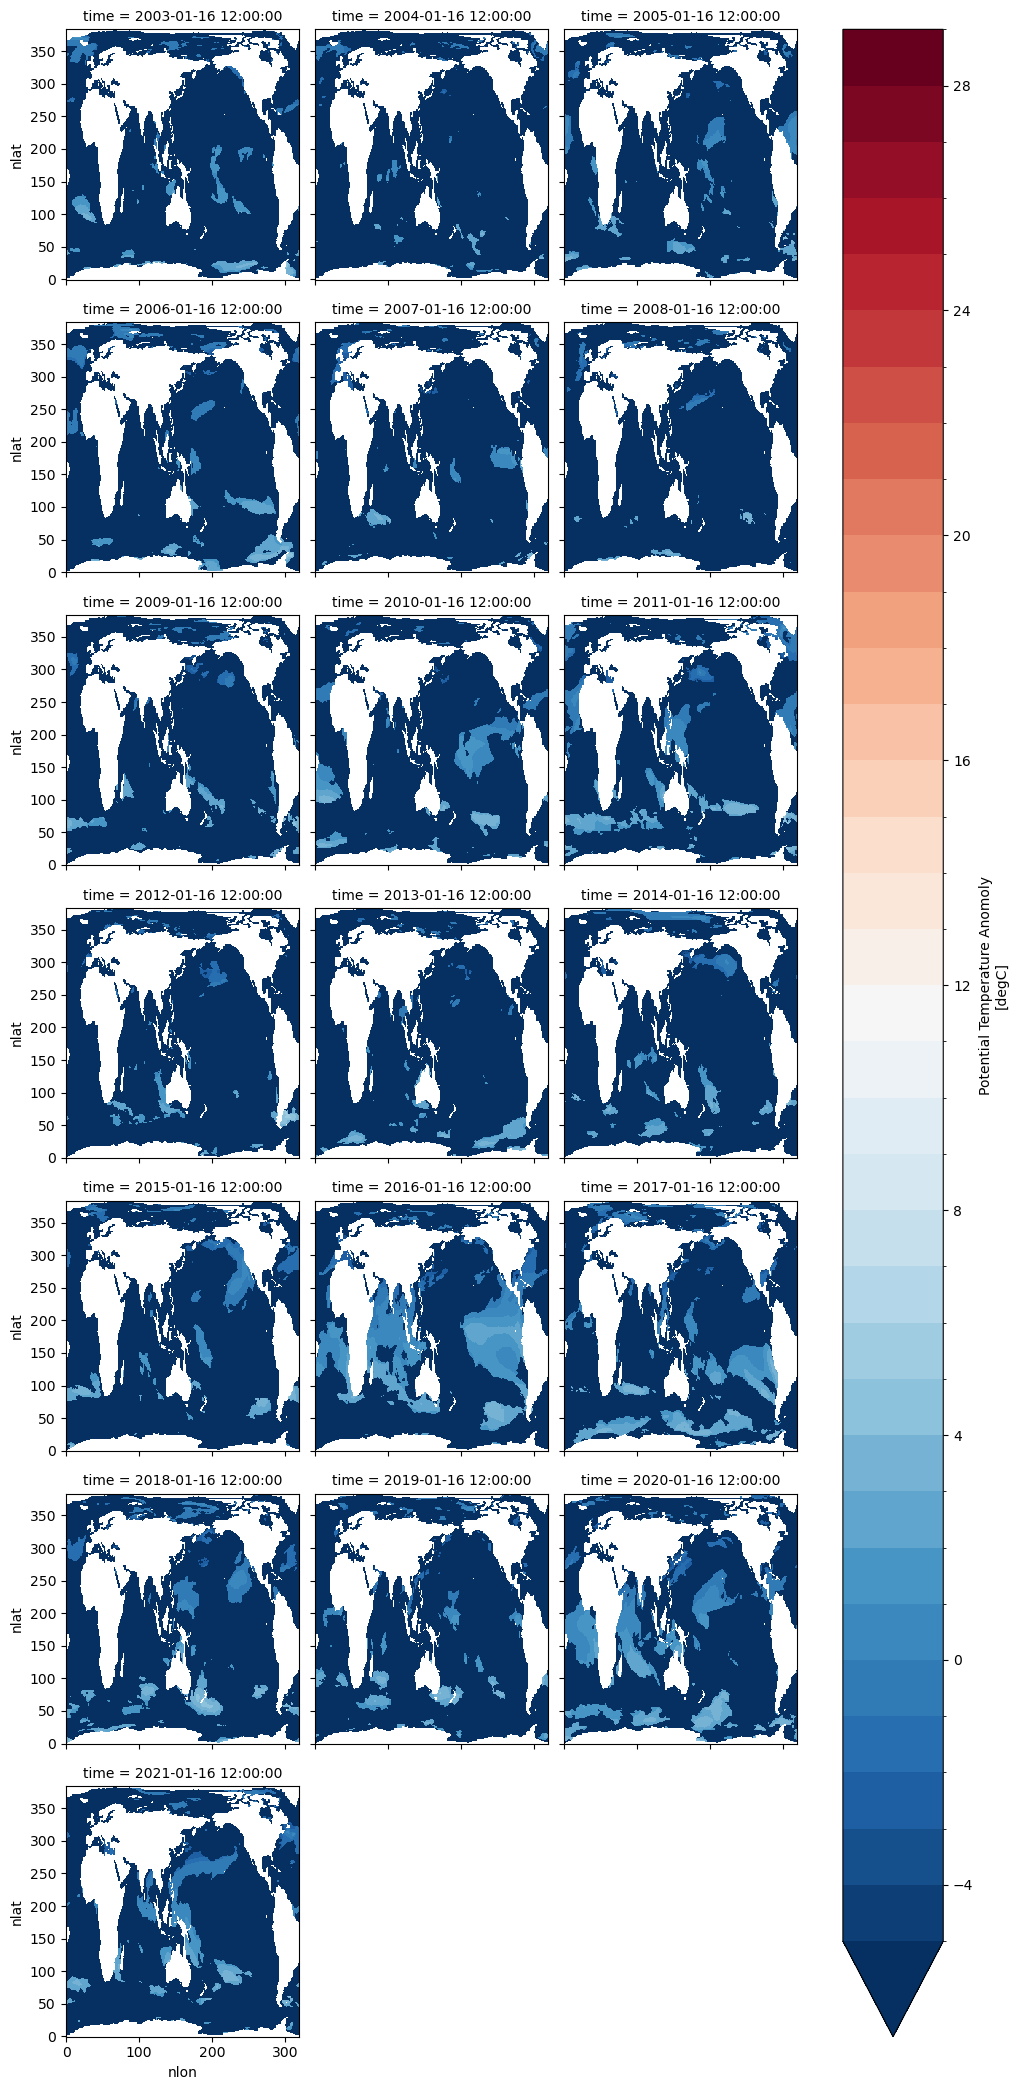

In [ ]:
ds_fosi.MHW.groupby("time.month")[1].plot(levels=np.arange(-5, 30, 1), col='time', col_wrap=3)


In [82]:

ds_fosi.MHW.groupby("time.month")[1].sel(nlat=100, nlon=275).values

array([-9.9990000e+03, -9.9990000e+03, -9.9990000e+03,  2.2773705e+00,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03, -9.9990000e+03,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03, -9.9990000e+03,
       -9.9990000e+03, -9.9990000e+03,  2.2694817e+00, -9.9990000e+03,
       -9.9990000e+03, -9.9990000e+03, -9.9990000e+03], dtype=float32)